<a href="https://colab.research.google.com/github/alvarobuchen/alvarobuchen-DataScience-GenAI-Submissions/blob/main/2_05_Exploratory_Data_Analysis%20COMPLETED.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=1xqQczl0FG-qtNA2_WQYuWePW9oU8irqJ)

# 2.05 Exploratory Data Analysis (EDA)
We have seen some early examples of EDA in the previous notebooks. This session will expand on this with more examples - specifically a dataset on the passengers of the Titanic, including whether each passenger survived. As such, we start by importing the data:

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from google.colab import files
upload = files.upload()

Saving titanic.csv to titanic (1).csv


We can now import the data into pandas as before:

In [5]:
titanic = pd.read_csv('titanic.csv')
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


We can find the number of rows and columns with ".shape":

In [6]:
titanic.shape

(891, 12)

891 rows and 12 columns - each row is a passenger. We can get information about the data using the _info_ function:

In [7]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


We can see from this our data items are of the type 'object' (meaning string), int64 (64-bit integers) or float64 (decimal numbers). There are 891 entries, but not every column has 891 non-null records: Age (714), Cabin (204) and Embarked (889) have fewer. This suggests there is missing data, which we can verify with code we used in our previous pandas' Notebooks:

In [8]:
titanic.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


We do have missing data: 177 missing values for Age, 687 for Cabin and 2 for Embarked. There are various options including deleting the rows (see the previous Notebook) affected or even deleting the columns. If we want to check if it's sensible to delete a column we may want to see the percentage of the column's data that is missing:

In [9]:
# Percent of data which is not available
titanic.isnull().sum()/len(titanic) * 100

,0
PassengerId,0.000000
Survived,0.000000
Pclass,0.000000
Name,0.000000
Sex,0.000000
Age,19.865320
SibSp,0.000000
Parch,0.000000
Ticket,0.000000
Fare,0.000000


Cabin is missing around 77% of its data, Age around 20% and Embarked only around 0.2%. We can find the number of unique and duplicated rows:

In [10]:
titanic.duplicated().value_counts()

,count
False,891


No duplicates (i.e. there are 891 records for which it's False that the record is a duplicate). Pandas will also give us summary statistics about this data:

In [11]:
titanic.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


We can see that only seven of the columns have been "described" ... the ones that are numeric (int64 or float64). For each, we get a range of useful measures including the mean average, the standard deviation, minimum and maximum values, and the 25th, 50th (median) and 75th percentiles. Some useful observations: the mean of Survived is 0.38, meaning only around 38% of passengers survived; the average age was around 30; and Fare ranges from 0 to over 512, with a median of only about 14, suggesting a few very expensive tickets.

### Visualising the Data

[]

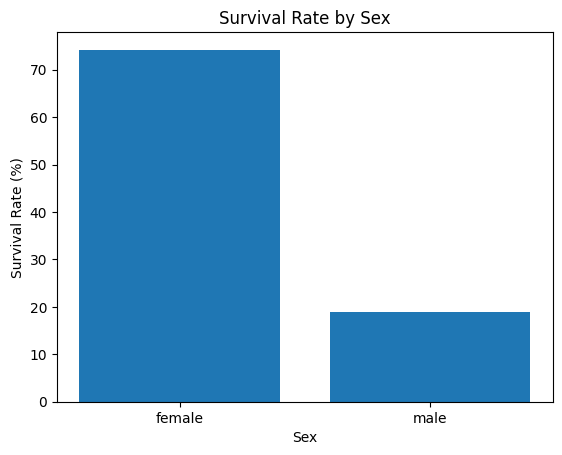

In [12]:
survival_by_sex = titanic.groupby('Sex')['Survived'].mean() * 100 # survival rate (%) for each sex
plt.bar(survival_by_sex.index, survival_by_sex.values) # create a bar chart of the two values
plt.xlabel('Sex') # x-axis is passenger sex
plt.ylabel('Survival Rate (%)') # y-axis is percentage who survived
plt.title('Survival Rate by Sex') # add title
plt.plot() # plot the chart to screen

There is a very large difference: around 74% of women survived compared to only around 19% of men, which fits the "women and children first" policy. Let's try another:

[]

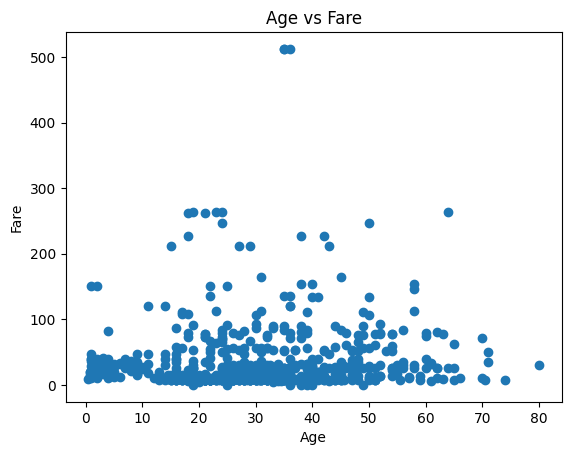

In [13]:
plt.scatter(titanic['Age'], titanic['Fare'])
plt.xlabel('Age')
plt.ylabel('Fare')
plt.title('Age vs Fare')
plt.plot()

Unlike the student data, there is very little correlation between age and fare (around 0.1) - older passengers did not pay much more for their tickets. Most fares are low, with a handful of very expensive tickets spread across all ages.

We may also want to see how "normal" our data is - i.e. does it follow a [normal distribution](https://en.wikipedia.org/wiki/Normal_distribution). Let's check with a histogram:

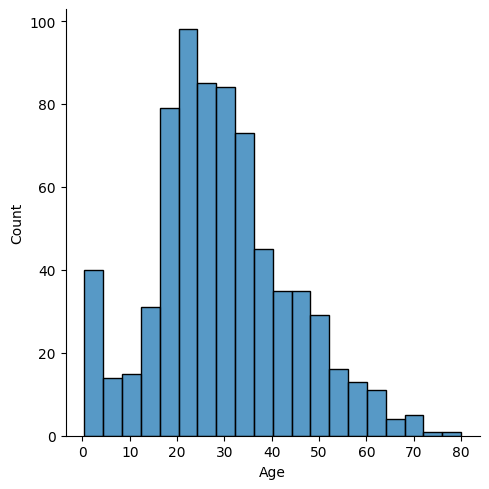

In [14]:
ax = sns.displot(titanic['Age'])

Age is fairly close to normal - slightly right-skewed, with a small bump of young children - so it's probably fine in practice.

We can use the _pairplot( )_ method to visualise pairs of variables. Here we colour each point by whether the passenger survived:

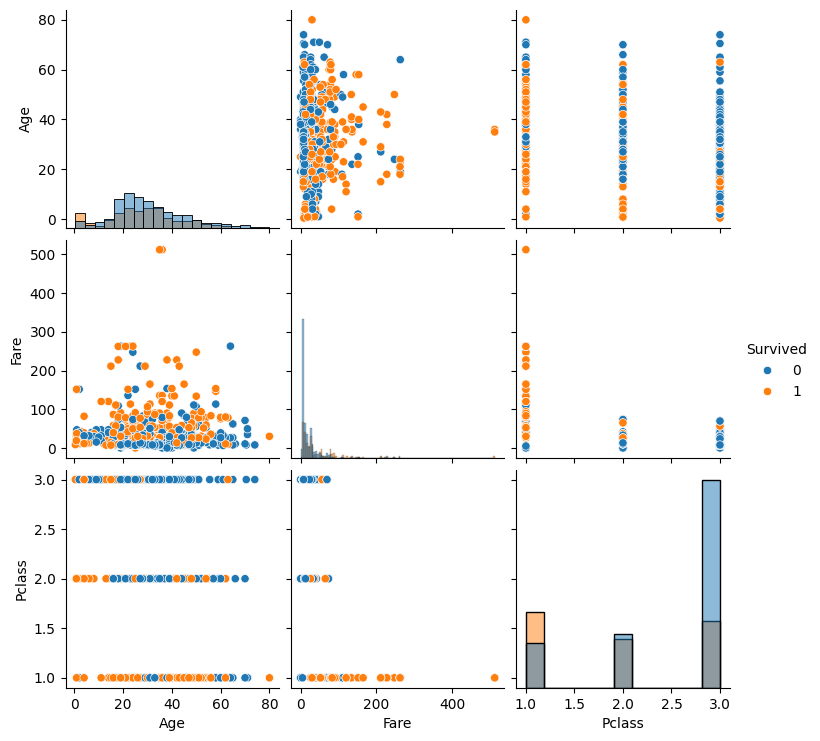

In [15]:
sns.pairplot(data = titanic[['Age','Fare','Pclass','Survived']], hue='Survived', diag_kind='hist')

Here we have the scatter plot when comparing two variables, and when it's only a single variable we have a histogram. As Pclass and Survived only take a few values, their plots appear as stripes rather than clouds of points. Survivors tend to have paid higher fares and to be in first class, while third-class passengers were much less likely to survive.

We may also decide to remove a variable:

In [16]:
titanic = titanic.drop(['Cabin'], axis=1)
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


We have dropped Cabin, as around 77% of its values were missing, making it of little use for analysis.

And that's it! There are of course many things we could do but this is a fairly typical example of an EDA process. Well done :)